In [ ]:
import matplotlib.pyplot as plt
from pydrake.systems.analysis import Simulator
from pydrake.systems.framework import DiagramBuilder
from pydrake.systems.primitives import LogVectorOutput
from pydrake.symbolic import Jacobian, Variable, sin, cos
from pydrake.math import RigidTransform, RotationMatrix
from volta.Leaf_systems.LIPMGaitGeneration import LIPMGaitGeneration
import numpy as np
from volta.robot.kinematics import *
from volta.utils import *
from pydrake.all import (
    DiagramBuilder,
    LeafSystem,
    BasicVector,
    LinearSystem,
    Simulator,
    PiecewisePolynomial
)
from pydrake.systems.primitives import LogVectorOutput
from volta.Leaf_systems.CubicTrajectory3D import CubicTrajectory3D
from volta.Leaf_systems.LIPMGaitGeneration import LIPMGaitGeneration
from volta.Leaf_systems.DummyParameters2 import DummyParameters2
from volta.utils import *

In [2]:
L1 = 0.054
L2 = 0.03
L3 = 0.1605
L4 = 0.166
L5 = 0.049
link_lengths = [L1,L2,L3,L4,L5]

In [3]:
def InitTrajectories(p_start, p_final, v_start, v_final, total_time):
    time = np.array([0.0, total_time])
    trajs = []
    for i in range(len(p_start)):
        P = np.array([[p_start[i],p_final[i]]])
        V = np.array([[v_start[i],v_final[i]]])
        trajs.append(PiecewisePolynomial.CubicHermite(time, P, V))
    return trajs

============

In [4]:
time_f = 5.0
time = np.array([0.0, 2.0, 3.0, time_f])
P = np.array([[0.0, 1.0, 1.0, -2.0]])
V_i = np.array([[0.0]])
V_f = np.array([[0.0]])
cubic = PiecewisePolynomial.CubicWithContinuousSecondDerivatives(time,P,V_i,V_f)

In [5]:
curr_t = 0.0
dt = 0.01
p = []
v = []
while curr_t <= time_f:
    p.append(cubic.value(curr_t)[0][0])
    v.append(cubic.EvalDerivative(curr_t, 1)[0][0])
    curr_t+=dt

In [6]:
p_arr = np.array([p])
v_arr = np.array([v])

In [7]:
CoM_P_L_start = [0.0, -0.054, 0.4055]
CoM_P_L_final = [0.0, 0.02, 0.35]
V = [0,0,0] 

In [8]:
sample_name = "step10cmV4_2"
loaded_data = np.load(f"/home/tanawatp/Documents/Thesis_simulation/Simulation/q_data/q_data_{sample_name}.npz")
q_L = loaded_data['arr_0'].T
q_R = loaded_data['arr_1'].T
T = loaded_data['arr_4'][0] 
q_R[:,-1] = q_R[:,-1] + (q_R[:,-1] - q_L[:,0])*0.5
q_L[:,-1] = q_L[:,-1] + (q_L[:,-1] - q_R[:,0])*0.5
loaded_qd_data = np.load(f"/home/tanawatp/Documents/Thesis_simulation/Simulation/q_data/qd_data_{sample_name}.npz")
qd_L = loaded_qd_data['arr_0'].T
qd_R = loaded_qd_data['arr_1'].T

In [9]:
# q_start = np.zeros(6)
# qd_start = np.zeros(6)
total_time = 2.0

# qL_final = q_L[:,0]
# qR_final = q_R[:,0]

# qdL_final = qd_L[:,0]
# qdR_final = qd_R[:,0]

In [10]:
curr_time = 0.0
dt = 0.01
# Trajs_R = InitTrajectories(p_start=CoM_P_R_start, 
#                                p_final=CoM_P_R_final,
#                                v_start=V,
#                                v_final=V,
#                                total_time=total_time
#                                )
Trajs_R = InitTrajectories(p_start=CoM_P_L_start, 
                               p_final=CoM_P_L_final,
                               v_start=V,
                               v_final=V,
                               total_time=total_time
                               )
QL = []
QdL = []
CoM_P_R_traj = []
QdR = []

st_P_sw0 = np.array([0.0, -2*0.054, 0.0])
Q_L = []
Q_R = []
c_P_sw = []
c_P_st = []
st_P_sw = []
actual_c_P_sw = []
actual_c_P_st = []
actual_st_P_sw = []

while curr_time <= total_time:
    temp_qL = []
    temp_qdL = []
    temp_qR = []
    temp_qdR = []
    for i in range(len(Trajs_R)):
        # temp_qL.append(Trajs_L[i].value(curr_time)[0][0])
        # temp_qdL.append(Trajs_L[i].EvalDerivative(curr_time, 1)[0][0])

        temp_qR.append(Trajs_R[i].value(curr_time)[0][0])
        temp_qdR.append(Trajs_R[i].EvalDerivative(curr_time, 1)[0][0])
    # QL.append(temp_qL)
    # QdL.append(temp_qdL)
    #====================================== IK ============================= 
    st_R_c = RotationMatrix.MakeZRotation(-np.pi/2.0)   
    st_T_c = RigidTransform(st_R_c, temp_qR)
    c_T_st = st_T_c.inverse()

    st_p_sw = st_P_sw0
    st_P_sw.append(st_p_sw)
    st_R_sw = RotationMatrix.MakeZRotation(0.0)
    st_T_sw = RigidTransform(st_R_sw, st_p_sw)

    c_T_sw = c_T_st @ st_T_sw
    R = RotationMatrix.MakeZRotation(np.pi/2.0) @ RotationMatrix.MakeYRotation(np.pi/2.0)
    th_L = CalcLegInverseKinematics(tform=RigidTransformToMatrix(RigidTransform(R ,c_T_st.translation())),
                                    link_lengths=link_lengths,
                                    is_left=True)
    th_R = CalcLegInverseKinematics(tform=RigidTransformToMatrix(RigidTransform(R ,c_T_sw.translation())),
                                    link_lengths=link_lengths,
                                    is_left=False)
       
    actual_c_P_sw.append(CalcLegForwardKinematics(joint_angles=th_L,link_lengths=link_lengths,is_left=True,forward_axis='y'))
    actual_c_P_st.append(CalcLegForwardKinematics(joint_angles=th_R,link_lengths=link_lengths,is_left=False,forward_axis='y'))
    actual_c_T_sw = RigidTransform(c_T_sw.rotation(),actual_c_P_sw[0])
    actual_st_T_sw = st_T_c @ actual_c_T_sw
    actual_st_P_sw.append(actual_st_T_sw.translation())
    c_P_sw.append(c_T_sw.translation())
    c_P_st.append(c_T_st.translation())
    Q_L.append(th_L)
    Q_R.append(th_R)

    CoM_P_R_traj.append(temp_qR)
    # QdR.append(temp_qdR)
    curr_time += dt

# qL_traj = np.array(QL).T
# qdL_traj = np.array(QdL).T
qR_traj = np.array(CoM_P_R_traj).T
qdR_traj = np.array(QdR).T

In [11]:
st_P_sw = np.array(st_P_sw)
actual_st_P_sw = np.array(actual_st_P_sw)
actual_c_P_sw = np.array(actual_c_P_sw)
actual_c_P_st = np.array(actual_c_P_st)
c_P_sw = np.array(c_P_sw)
c_P_st = np.array(c_P_st)
q_l = np.array(Q_L).T
q_r = np.array(Q_R).T

In [12]:
def InitTrajectories(p_start, p_final, v_start, v_final, total_time):
    time = np.array([0.0, total_time])
    trajs = []
    for i in range(len(p_start)):
        P = np.array([[p_start[i],p_final[i]]])
        V = np.array([[v_start[i],v_final[i]]])
        trajs.append(PiecewisePolynomial.CubicHermite(time, P, V))
    return trajs

def InitTrajectories2(P, V, Times, n):
    trajs = []
    for i in range(n):
        trajs.append(PiecewisePolynomial.CubicHermite(np.array(Times), 
                                                      np.array([P[i,:]]), 
                                                      np.array([V[i,:]])))
    return trajs

def InitContinuousSecondDerivativesTrajectories(P, V_i, V_f, Times:list,n):
    trajs = []
    for i in range(n):
        trajs.append(PiecewisePolynomial.CubicWithContinuousSecondDerivatives(np.array(Times),
                                                                              np.array([P[i,:]]),
                                                                              np.array([[V_i[i]]]),
                                                                              np.array([[V_f[i]]])))
    return trajs

In [13]:
step_length = 0.1
# CoM_P_sw_viapoints0 = [0.054*2.0 + 0.02, 0.0, -0.35, 1]
# CoM_P_sw_viapoints1 = [0.054*2.0 + 0.02, (step_length-0.05)*0.5, -0.35+0.05, 1]
# CoM_P_sw_viapoints2 = [0.054*2.0 + 0.02, (step_length-0.05), -0.35, 1]
CoM_P_sw_viapoints0 = [0.054*2.0 + 0.02, 0.0, -0.35, 1]
CoM_P_sw_viapoints1 = [0.054*2.0 + 0.02, (step_length)*0.5, -0.35+0.05, 1]
CoM_P_sw_viapoints2 = [0.054*2.0 + 0.02, (step_length), -0.35, 1]
viapoints = [CoM_P_sw_viapoints0, CoM_P_sw_viapoints1, CoM_P_sw_viapoints2]
q_halfstep = []
body_R_foot = np.array([
                        [0,-1, 0],
                        [0, 0, 1],
                        [-1,0, 0],
                        [0, 0, 0]])
for i in viapoints:
    body_P_Rfoot = np.array([i]).T
    body_T_Rfoot = np.concatenate((body_R_foot,body_P_Rfoot),axis=1)
    th_R = CalcLegInverseKinematics(tform=body_T_Rfoot,link_lengths=link_lengths,is_left=False)
    q_halfstep.append(th_R)
    
q_halfstep = np.array(q_halfstep).T


In [14]:
body_P_Lfoot_init = np.array([[-0.054, 0.0, -0.26, 1]]).T
body_T_Lfoot_init = np.concatenate((body_R_foot,body_P_Lfoot_init),axis=1)

body_P_Rfoot_init = np.array([[0.054, 0.0, -0.26, 1]]).T
body_T_Rfoot_init = np.concatenate((body_R_foot,body_P_Rfoot_init),axis=1)

In [15]:
# q_L_init = q_l[:,0]
q_L_init = CalcLegInverseKinematics(tform=body_T_Lfoot_init,link_lengths=link_lengths,is_left=True)
q_L_0 = q_l[:,-1]
q_L_1 = q_L_0
q_L_2 = q_L_0
q_L_3 = q_L[:,0]

# q_R_init = q_r[:,0]
q_R_init = CalcLegInverseKinematics(tform=body_T_Rfoot_init,link_lengths=link_lengths,is_left=False)
q_R_0 = q_r[:,-1]
q_R_1 = q_halfstep[:,1]
q_R_2 = q_halfstep[:,2]
q_R_3 = q_R[:,0]


In [20]:
body_P_Lfoot_init = np.array([[0.02, 0.0, -0.35, 1]]).T
body_T_Lfoot_init = np.concatenate((body_R_foot,body_P_Lfoot_init),axis=1)


In [21]:
CalcLegInverseKinematics(tform=body_T_Lfoot_init,link_lengths=link_lengths,is_left=True)

array([ 0.        ,  0.26656426,  0.54479874, -1.06963947,  0.52484073,
        0.26656426])

In [18]:
q_L_0

array([ 0.        ,  0.26654137,  0.54478309, -1.06960887,  0.52482578,
        0.26654137])

In [16]:
q_L_viapoints = np.array([q_L_init,
                           q_L_0,
                           q_L_1,
                           q_L_2,
                           q_L_3]).T

q_R_viapoints = np.array([ q_R_0,
                           q_R_1,
                           q_R_2,
                           q_R_3]).T
qd = np.zeros(6)
qd_L_end = qd_L[:,0]
qd_R_end = qd_R[:,0]
Times = [0.0, 2.0, 3.0, 4.0, 5.0]
# Times = [0.0, 2.0, 3.0, 3.5, 4.0, 5.0]

In [17]:
temp0 = np.zeros([4,6])
qd_L_viapoints = np.concatenate((temp0,np.array([qd_L_end]))).T

In [18]:
qL_trajs_new = InitTrajectories2(P= q_L_viapoints,
                                 V= qd_L_viapoints,
                                 Times= Times,
                                 n= 6)

qR_trajs_new = InitContinuousSecondDerivativesTrajectories(P= q_R_viapoints,
                                                           V_i= qd,
                                                           V_f= qd_R_end,
                                                           Times= Times[1:],
                                                           n= 6)
qR_trajs_new0 = InitTrajectories(p_start=q_R_init,
                                 p_final=q_R_0,
                                 v_start=qd,
                                 v_final=qd,
                                 total_time=Times[1])
Q_L_new = []
Qd_L_new = []
Q_R_new = []
Qd_R_new = []
CoM_P = []
curr_time = 0.0
while curr_time <= Times[-1]:
    temp_qL = []
    temp_qdL = []
    temp_qR = []
    temp_qdR = []
    if curr_time <= Times[1]:
        temp_traj_R = qR_trajs_new0
    else:
        temp_traj_R = qR_trajs_new
    for i in range(len(qL_trajs_new)):
        temp_qL.append(qL_trajs_new[i].value(curr_time)[0][0])
        temp_qdL.append(qL_trajs_new[i].EvalDerivative(curr_time, 1)[0][0])

        temp_qR.append(temp_traj_R[i].value(curr_time)[0][0])
        temp_qdR.append(temp_traj_R[i].EvalDerivative(curr_time, 1)[0][0])

    Q_L_new.append(temp_qL)
    Qd_L_new.append(temp_qdL)
    Q_R_new.append(temp_qR)
    Qd_R_new.append(temp_qdR)

    CoM_P.append(CalcLegForwardKinematics(joint_angles=temp_qL,
                                          link_lengths=link_lengths,
                                          is_left=True,
                                          forward_axis='x'))
    curr_time += dt

In [19]:
q_L_new = np.array(Q_L_new).T
qd_L_new = np.array(Qd_L_new).T
q_R_new = np.array(Q_R_new).T
qd_R_new = np.array(Qd_R_new).T
CoM_P = np.array(CoM_P).T

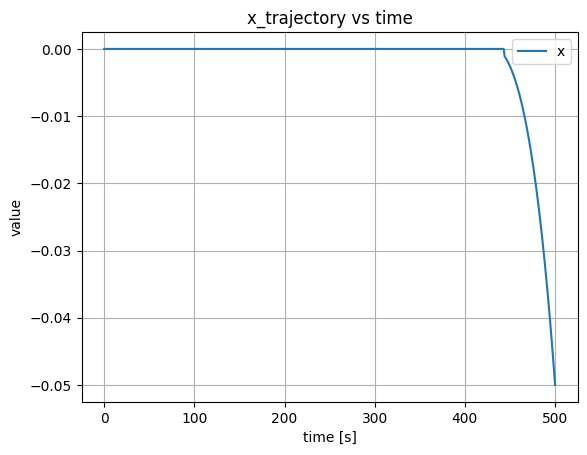

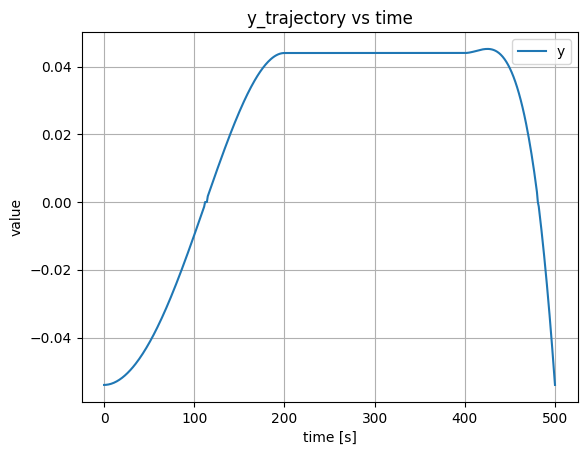

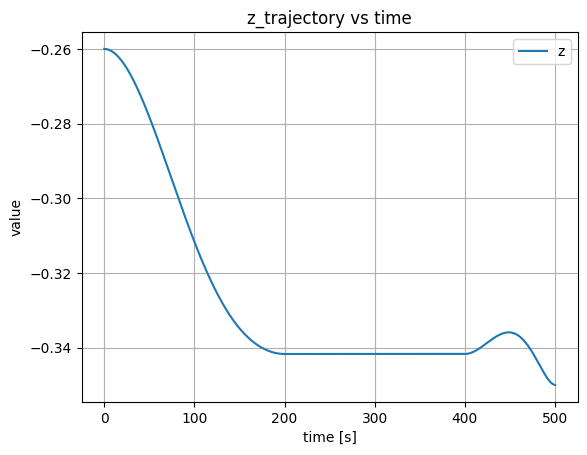

In [20]:
name = ["x","y","z"]

for i in range(len(name)):
    temp = name[i]
    plt.plot(CoM_P[i,:],label = f"{temp}")
    plt.xlabel("time [s]")
    plt.ylabel("value")
    plt.title(f"{temp}_trajectory vs time")
    plt.legend()
    plt.grid()
    plt.show()

### L

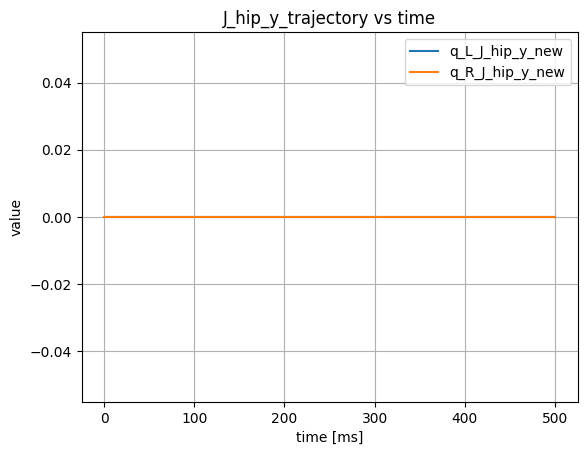

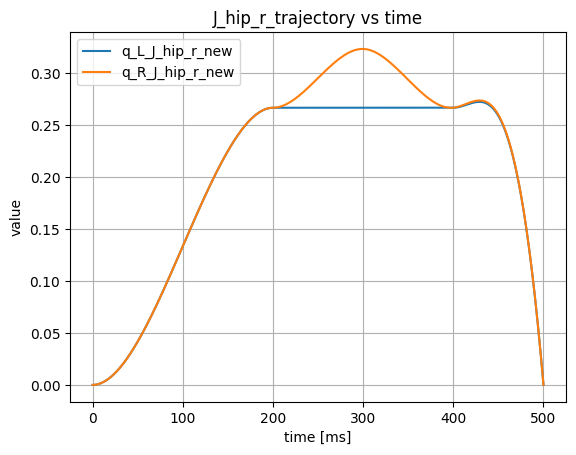

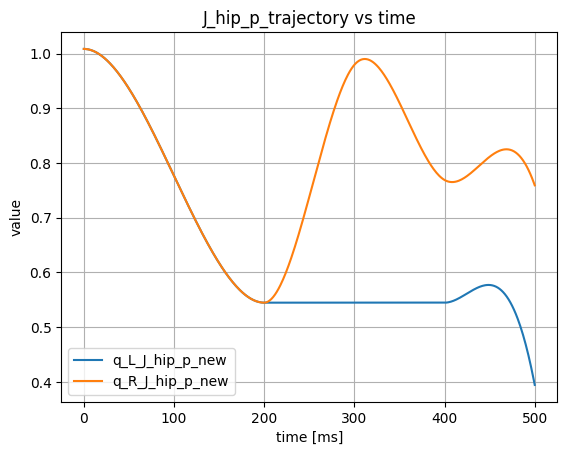

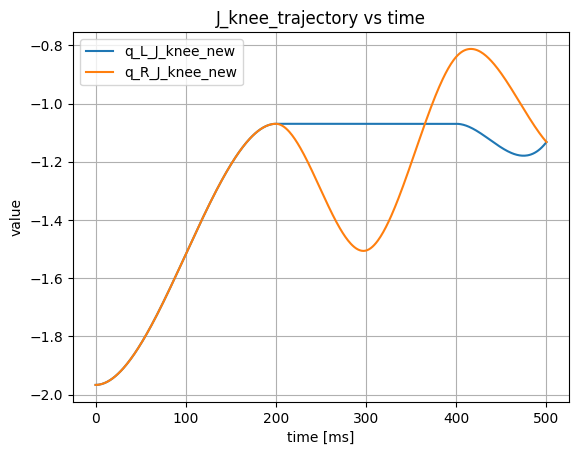

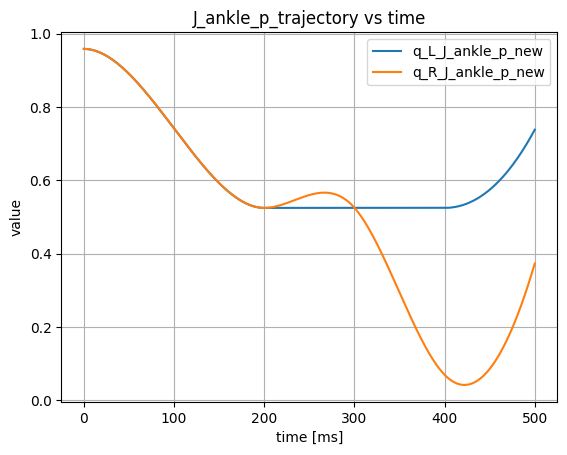

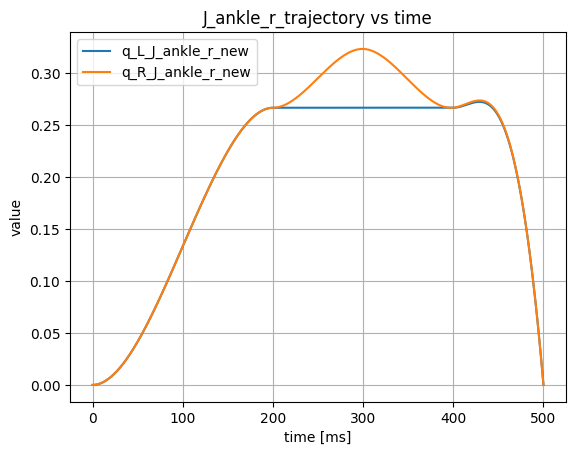

In [21]:
name = ["J_hip_y","J_hip_r","J_hip_p","J_knee","J_ankle_p","J_ankle_r"]
for i in range(len(name)):
    temp = name[i]
    # plt.plot(q_L[i,:],label = f"q_{temp}")
    # plt.plot(qd_L[i,:],label = f"qd_{temp}")
    plt.plot(q_L_new[i,:],label = f"q_L_{temp}_new")
    plt.plot(q_R_new[i,:],label = f"q_R_{temp}_new")
    # plt.plot(qd_L_new[i,:],label = f"qd_{temp}_new")
    # plt.plot(q_R[i,:],label = q_label)
    plt.xlabel("time [ms]")
    plt.ylabel("value")
    plt.title(f"{temp}_trajectory vs time")
    plt.legend()
    plt.grid()
    plt.show()

### R

In [22]:
q_R[i,:].shape

(563,)

In [23]:
q_R_new[i,:].shape

(501,)

In [24]:
n = np.concatenate((q_R_new[i,:],q_R[i,:]))

In [25]:
n.shape

(1064,)

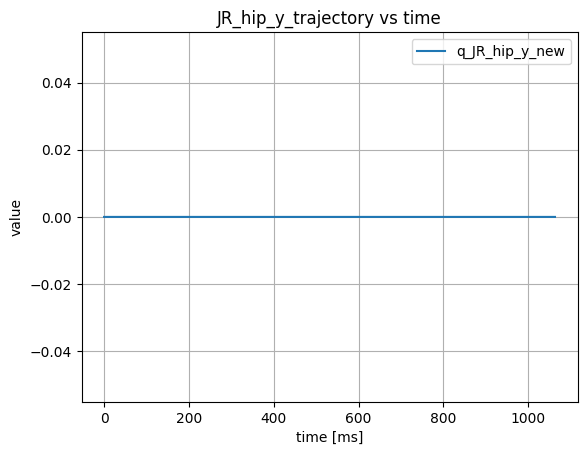

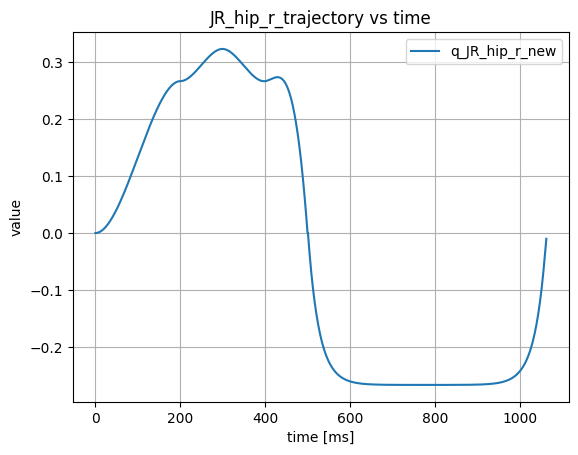

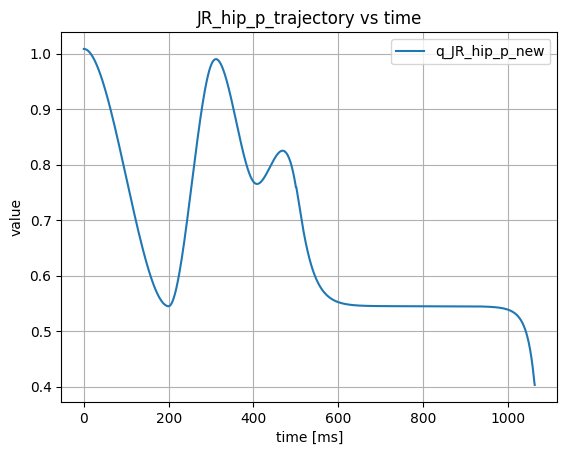

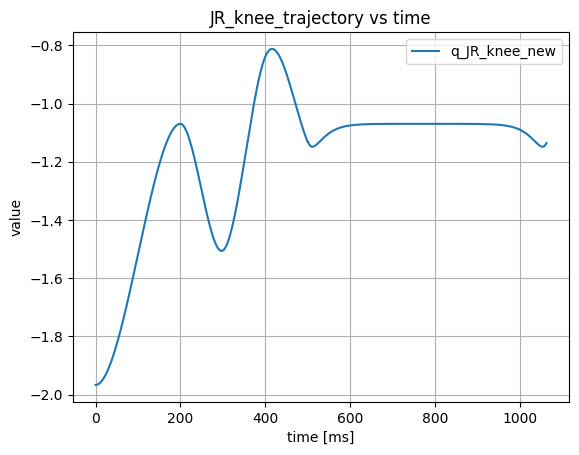

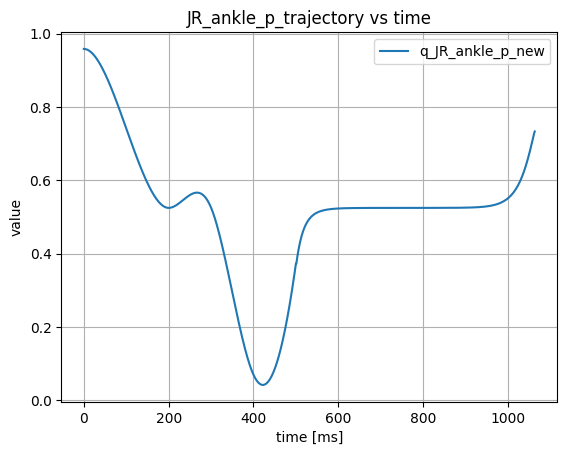

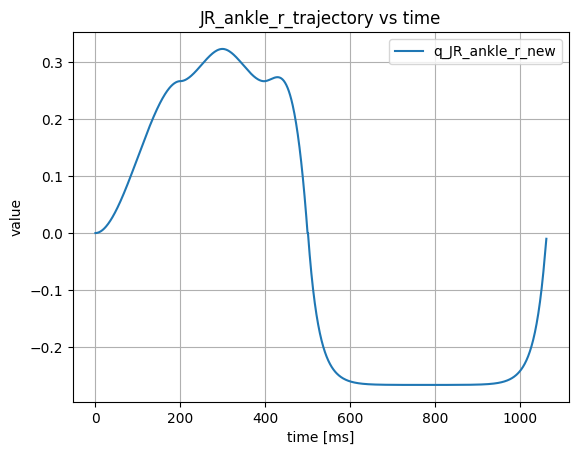

In [26]:
name = ["JR_hip_y","JR_hip_r","JR_hip_p","JR_knee","JR_ankle_p","JR_ankle_r"]
for i in range(len(name)):
    temp = name[i]
    plt.plot(np.concatenate((q_R_new[i,:],q_R[i,:])),label = f"q_{temp}_new")
    # plt.plot(np.concatenate((qd_R_new[i,:],qd_R[i,:])),label = f"qd_{temp}_new")
    plt.xlabel("time [ms]")
    plt.ylabel("value")
    plt.title(f"{temp}_trajectory vs time")
    plt.legend()
    plt.grid()
    plt.show()

In [ ]:
import numpy as np

def TestObservability(A, C):
    """
    Tests the observability of a LTI system (A, C).
    
    Returns:
        is_observable (bool): True if the system is observable.
        rank (int): The rank of the observability matrix.
        obs_matrix (ndarray): The calculated observability matrix.
    """
    n = A.shape[0]
    # Construct the matrix: [C, CA, CA^2, ..., CA^(n-1)]^T
    obs_matrix = np.vstack([C @ np.linalg.matrix_power(A, i) for i in range(n)])
    
    rank = np.linalg.matrix_rank(obs_matrix)
    is_observable = (rank == n)
    
    return is_observable, rank, obs_matrix


In [5]:
eta = np.sqrt(9.81/0.35)
A = np.identity(3) + 0.001 * np.array([[0, 1, 0], [eta**2, 0, -eta**2], [0, 0, 0]])
C = np.array([[1, 1, 1]])
observable, r, o = TestObservability(A, C)
print(f"Observable: {observable} (Rank: {r})")

Observable: True (Rank: 3)


In [6]:
o

array([[1.        , 1.        , 1.        ],
       [1.02802857, 1.001     , 0.97197143],
       [1.05608517, 1.00202803, 0.94391483]])

In [3]:
A

array([[ 1.        ,  0.001     ,  0.        ],
       [ 0.02802857,  1.        , -0.02802857],
       [ 0.        ,  0.        ,  1.        ]])